# DDS and FFT together, over the air (tutorial, part 3)

This notebook belongs to `tutorial/TUTORIAL_DDS_FFT.md`. The overlay contains **both** blocks you built in the first two tutorials:

```
 Python --registers--> DDS --> TX1 ~~~ antenna / cable ~~~ RX1 --> FFT --> DMA --> Python
        (frequency, amplitude)      the radio                 (spectra computed in the FPGA)
```

No sample ever passes through Python in this loop: the tone is generated in the FPGA and the spectrum is computed in the FPGA. Python sets a frequency and reads
power spectra. The only software left on the radio is the one-time AD9361 configuration over SPI (`p501_radio.bring_up`), without which the chip produces no clock.

| test | what it shows |
|---|---|
| 0 | the overlay holds both blocks at their addresses |
| 1 | the AD9361 comes up with one call, and the tone is clean (measured by the FFT in the FPGA) |
| 2 | the tone lands in the FFT bin it belongs to, for positive and negative frequencies and neighbouring bins |
| 3 | the FFT sees the amplitude steps of the DDS (6.02 dB per halving) |
| 4 | switching the DDS off removes the tone from the spectrum |
| 5 | a frequency change is visible in the next spectrum, and reading 256 frames takes milliseconds |

**Setup:** TX1 and RX1 antennas near each other, or a cable with at least 40 dB attenuation: never connect them directly.

## Configuration

In [1]:
BIT         = "/home/xilinx/jupyter_notebooks/p501_fft_dds/p501_fft_dds.bit"   # overlay with the DDS and the FFT (the .hwh next to it)
NFFT_LOG2   = 10                 # FFT length 2^10 = 1024: must equal the value the overlay was built with
FS          = 3_840_000          # sample rate (3.84 MSPS)
LO          = 700_000_000        # RF centre frequency, Hz
RF_BW       = 4_000_000          # analog bandwidth, Hz
TX_ATTEN    = 10                 # dB
RX_GAIN     = 45                 # gain-table index 0..76
SETTLE_BIN  = 267                # test tone of the bring-up: exactly on this FFT bin

## Test 0 - load the overlay

`Overlay(BIT)` programs the PL. `P501Dds` and `P501Fft` are thin wrappers (`p501_dds.py`, `p501_fft.py`): the first writes the DDS registers, the second starts the
FFT DMA and reads the 32-bit power values of the frames.

In [2]:
import sys, time
import numpy as np
import matplotlib.pyplot as plt
from pynq import Overlay

sys.path.insert(0, '/home/xilinx/jupyter_notebooks')
sys.path.insert(0, '/home/xilinx/jupyter_notebooks/p501_fft_dds')       # p501_radio.py, p501_dds.py, p501_fft.py
import p501_radio
from p501_dds import P501Dds
from p501_fft import P501Fft

results = {}
def check(name, ok, detail):
    results[name] = (bool(ok), detail)
    print(f"{'PASS' if ok else 'FAIL'}  {name}: {detail}")

ol  = Overlay(BIT)                                   # programs the PL: DDS + FFT chain + the base design
dds = P501Dds(ol.dds_regs, FS)                       # tone generator  (registers at 0x9C450000)
fft = P501Fft(ol.fft_dma, NFFT_LOG2, FS)             # spectrum reader (DMA at 0x9C440000)

def tone(freq_hz=None, amp=None, enable=None, wait_s=0.003):
    """dds.set(...), then wait: the radio chain and the FFT pipeline still hold about two frames (0.5 ms) of the old signal."""
    dds.set(freq_hz=freq_hz, amp=amp, enable=enable)
    time.sleep(wait_s)

a_fft, a_dds = ol.ip_dict["fft_dma"]["phys_addr"], ol.ip_dict["dds_regs"]["phys_addr"]
check("both blocks in the overlay", a_fft == 0x9C440000 and a_dds == 0x9C450000, f"fft_dma at 0x{a_fft:08X}, dds_regs at 0x{a_dds:08X}")

PASS  both blocks in the overlay: fft_dma at 0x9C440000, dds_regs at 0x9C450000


## Test 1 - bring up the AD9361 in one call

`p501_radio.bring_up(ol)` is the whole software side of the radio. `settle` repeats the TX/RX start until the test tone is clean: the quality measure is
`fft.image_rejection_db(...)`, the spectrum computed by the FPGA.

In [3]:
F_SETTLE = SETTLE_BIN * fft.bin_hz                   # a tone exactly on an FFT bin: no leakage into the neighbours

def measure():
    """Image rejection of the test tone, from the FFT frames computed in the FPGA."""
    tone(freq_hz=F_SETTLE, amp=0.5)
    return fft.image_rejection_db(fft.average(8), F_SETTLE)

ad = p501_radio.bring_up(ol, LO, RF_BW, TX_ATTEN, RX_GAIN)       # the AD9361 is configured over SPI: one call
rej, tries = p501_radio.settle(ad, ol, measure)                  # repeat until the tone is clean (known AD9361 analog-state issue)
print(f"settled after {tries} tries, image rejection {rej:.1f} dB")
check("AD9361 up", ad.info["ok"], f"LO locks {ad.info['rx_lock']}/{ad.info['tx_lock']}, ENSM 0x{ad.info['ensm']:X}, calibrations {ad.info['calibrations']}")

settled after 30 tries, image rejection 59.7 dB
PASS  AD9361 up: LO locks True/True, ENSM 0xA, calibrations {'rx_bb_filter': True, 'tx_bb_filter': True, 'bb_dc': True, 'rf_dc': True, 'tx_quad': 3}


### A first look

64 frames from the FPGA: the spectrum of the tone you hear, a waterfall of the individual frames, and the DC spike the AD9361 always has (LO leakage).

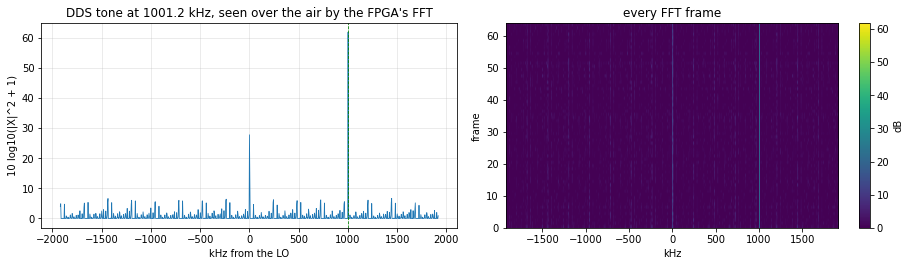

PASS  tone over the air: peak at 1001.25 kHz, 62 dB over the floor, image rejection 58.3 dB


In [4]:
ok, P = fft.read_frames(64)
avg = np.fft.fftshift(P.mean(axis=0)); db = fft.db(avg)
f_pk, l_pk = fft.peak(avg)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].plot(fft.freqs / 1e3, db, lw=0.8); ax[0].axvline(F_SETTLE / 1e3, color="g", ls="--", lw=0.8)
ax[0].set(title=f"DDS tone at {F_SETTLE/1e3:.1f} kHz, seen over the air by the FPGA's FFT", xlabel="kHz from the LO", ylabel="10 log10(|X|^2 + 1)"); ax[0].grid(alpha=.3)
im = ax[1].imshow(fft.db(np.fft.fftshift(P, axes=1)), aspect="auto", origin="lower", cmap="viridis", extent=[fft.freqs[0] / 1e3, fft.freqs[-1] / 1e3, 0, 64])
ax[1].set(title="every FFT frame", xlabel="kHz", ylabel="frame"); fig.colorbar(im, ax=ax[1], label="dB")
plt.tight_layout(); plt.show()
floor = float(np.median(db))
check("tone over the air", ok and abs(f_pk - F_SETTLE) < fft.bin_hz / 2 and l_pk - floor > 30,
      f"peak at {f_pk/1e3:.2f} kHz, {l_pk - floor:.0f} dB over the floor, image rejection {fft.image_rejection_db(avg, F_SETTLE):.1f} dB")

## Test 2 - the right bin, for positive and negative frequencies

The DDS frequency is set to exactly `k * fs / N` for seven bins `k`, including negative ones and two neighbours (267 and 268). The FFT peak must be on bin `k`.
A swapped I/Q order would put every tone on bin `-k`.

PASS  tone in the right bin: set -400 -> bin -400 (62 dB); set -300 -> bin -300 (62 dB); set -100 -> bin -100 (62 dB); set +100 -> bin +100 (62 dB); set +267 -> bin +267 (62 dB); set +268 -> bin +268 (62 dB); set +400 -> bin +400 (61 dB)


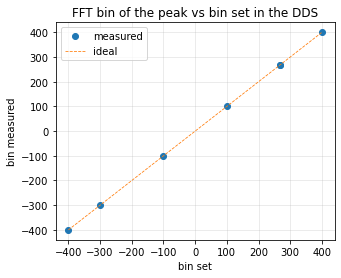

In [5]:
bins = [-400, -300, -100, 100, 267, 268, 400]
found = []
for k in bins:
    tone(freq_hz=k * fft.bin_hz, amp=0.5)
    avg = fft.average(8)
    f_pk, l_pk = fft.peak(avg)
    found.append((k, round(f_pk / fft.bin_hz), l_pk - float(np.median(fft.db(avg)))))
check("tone in the right bin", all(k == kp and m > 30 for k, kp, m in found),
      "; ".join(f"set {k:+d} -> bin {kp:+d} ({m:.0f} dB)" for k, kp, m in found))
fig, ax = plt.subplots(figsize=(5, 4))
ax.plot([k for k, _, _ in found], [kp for _, kp, _ in found], "o", label="measured"); ax.plot(bins, bins, "--", lw=0.8, label="ideal")
ax.set(title="FFT bin of the peak vs bin set in the DDS", xlabel="bin set", ylabel="bin measured"); ax.legend(); ax.grid(alpha=.3)
plt.show()

## Test 3 - amplitude steps

The amplitude register halves four times; the FFT bin power must fall by 6.02 dB each time (power is amplitude squared).

PASS  amplitude steps of 6 dB: steps: 6.06 dB, 6.01 dB, 5.96 dB


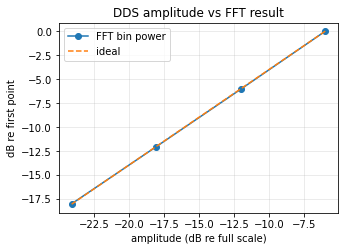

In [6]:
amps = [0.5, 0.25, 0.125, 0.0625]
k0 = SETTLE_BIN
lev = []
for a in amps:
    tone(freq_hz=k0 * fft.bin_hz, amp=a)
    avg = fft.average(16)
    lev.append(float(fft.db(avg)[k0 + fft.n // 2]))
steps = -np.diff(lev)
check("amplitude steps of 6 dB", np.abs(steps - 6.02).max() < 1.0, "steps: " + ", ".join(f"{s:.2f} dB" for s in steps))
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(20 * np.log10(amps), np.array(lev) - lev[0], "o-", label="FFT bin power"); ax.plot(20 * np.log10(amps), 20 * np.log10(np.array(amps) / amps[0]), "--", label="ideal")
ax.set(title="DDS amplitude vs FFT result", xlabel="amplitude (dB re full scale)", ylabel="dB re first point"); ax.legend(); ax.grid(alpha=.3)
plt.show()

## Test 4 - off means off

`dds.off()` sends zeros to the DAC; the tone must disappear from the spectrum (the transmitter stays powered, so a weak LO carrier remains at DC).

In [7]:
tone(freq_hz=k0 * fft.bin_hz, amp=0.5)
l_on = float(fft.db(fft.average(16))[k0 + fft.n // 2])
tone(enable=False)
avg = fft.average(16)
l_off = float(fft.db(avg)[k0 + fft.n // 2])
check("off removes the tone", l_on - l_off > 30, f"{l_on:.0f} dB with the tone, {l_off:.0f} dB when off")

PASS  off removes the tone: 62 dB with the tone, 0 dB when off


## Test 5 - speed

A frequency change shows in the spectrum after about two frames (0.5 ms: the receive chain and the FFT pipeline still hold the old signal), and the FFT DMA delivers whole frames fast: at 3.84 MSPS one 1024-point frame lasts 267 µs. We time 256 frames
and ten frequency changes with a spectrum read after each.

In [8]:
t0 = time.perf_counter(); ok, P = fft.read_frames(256); t_256 = time.perf_counter() - t0
sweep_bins = [-380, -250, -120, 120, 250, 380, -330, 180, -60, 330]
good = 0; t0 = time.perf_counter()
for k in sweep_bins:
    tone(freq_hz=k * fft.bin_hz, amp=0.5)
    good += round(fft.peak(fft.average(4))[0] / fft.bin_hz) == k
t_chg = (time.perf_counter() - t0) / len(sweep_bins)
check("fast updates", ok and good == len(sweep_bins) and t_256 < 1.0,
      f"256 frames in {t_256*1e3:.1f} ms; {good}/{len(sweep_bins)} frequency changes seen in the next spectrum, {t_chg*1e3:.1f} ms per change + 4-frame read")
dds.off()

PASS  fast updates: 256 frames in 82.5 ms; 10/10 frequency changes seen in the next spectrum, 9.3 ms per change + 4-frame read


## Summary

In [9]:
bad = [k for k, (ok, _) in results.items() if not ok]
print("ALL TESTS PASSED" if not bad else "SOME TESTS FAILED: " + ", ".join(bad))

ALL TESTS PASSED


### If a test fails

| symptom | likely cause |
|---|---|
| `Overlay(BIT)` error about connections | the `.hwh` was not fixed with `tools/fix_hwh.py` |
| `ip_dict` lacks `fft_dma` or `dds_regs`, or other addresses | the overlay is not the combined one (`FFT=1 DDS=1`), or the DDS was added to a design with different ports |
| `TimeoutError` from `dds.set` or `fft.average` | the AD9361 clock is not running: run `p501_radio.bring_up` first |
| test 1: tone weak / not found | antennas or cable, TX attenuation, LO. Test with the digital loopback (`p501_radio.loopback(ad, True)`) to separate RF from FPGA |
| test 2: peak on `-k` | I and Q swapped somewhere |
| test 2: peak off by a bin | `FS` or `NFFT_LOG2` in the configuration differ from the real sample rate / the overlay |
| test 3: steps not 6 dB | the FFT saturates (raise `fft_scale_shift` and rebuild) or the low-amplitude tone is at the noise floor |